# NumPy로 직접 구현한 MNIST 인공신경망
**황태하 | 딥러닝 과제 | 2026-10-27**

## 1. 과제 개요와 연구 목적
28×28 손글씨 숫자를 0~9로 분류하는 다층 퍼셉트론(MLP)을 직접 설계한다.
NumPy 행렬 연산으로 순전파, 역전파, 미니배치 경사하강법을 구현하고,
은닉층·학습률·배치 크기를 바꾸어 정확도와 계산량을 비교한다. 최종 목표는 공식 테스트 정확도 80% 이상이다.

검증 정확도로만 모델을 선정하며 테스트 데이터는 마지막 평가 전까지 학습·튜닝에 사용하지 않는다.
노트북 자체가 전체 소스코드와 실제 실행 결과를 담는다. 별도 모델 구현 파일은 필요하지 않다.

## 2. 실행 방법과 재현성
VS Code에서 Python 커널을 선택하고 **모두 실행**한다. 필요한 패키지는 `numpy`, `matplotlib`, `pandas`,
`threadpoolctl`, `ipykernel`이다. 누락 시 해당 커널의 환경에 설치한다.
MNIST는 `.mnist_work/data/mnist.npz`에 캐시하고 없으면 자동 다운로드한다.
실행 결과 JSON·그림은 `.mnist_work/results/`에 저장되며 Git에서 제외된다.
난수 시드는 42, 공통 에포크 수는 10이다. 하드웨어와 BLAS 구현에 따라 시간 및 미세한 수치는 달라질 수 있다.

In [1]:
import hashlib
import json
import platform
import sys
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits, threadpool_info

get_ipython().run_line_magic('matplotlib', 'inline')

SEED, EPOCHS = 42, 10
WORK = Path.cwd() / '.mnist_work'
DATA, OUT = WORK / 'data', WORK / 'results'
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
# 작은 행렬의 과도한 스레드 생성 비용을 줄이고 비교 조건을 고정한다.
blas_limit = threadpool_limits(limits=1, user_api='blas')
plt.rcParams.update({'font.size':10, 'figure.dpi':110, 'axes.unicode_minus':False})
if Path('C:/Windows/Fonts/malgun.ttf').exists():
    font_manager.fontManager.addfont('C:/Windows/Fonts/malgun.ttf')
    plt.rcParams['font.family'] = 'Malgun Gothic'
environment = {'python':platform.python_version(), 'numpy':np.__version__,
               'pandas':pd.__version__, 'matplotlib':matplotlib.__version__,
               'platform':platform.platform(), 'seed':SEED, 'blas_threads':1,
               'blas':threadpool_info()}
print(json.dumps(environment, ensure_ascii=False, indent=2))

def figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / (name+'.png'), dpi=170, bbox_inches='tight')
    display(fig)
    plt.close(fig)

{
  "python": "3.14.4",
  "numpy": "2.4.6",
  "pandas": "3.0.3",
  "matplotlib": "3.10.9",
  "platform": "Windows-10-10.0.19045-SP0",
  "seed": 42,
  "blas_threads": 1,
  "blas": [
    {
      "user_api": "blas",
      "internal_api": "openblas",
      "num_threads": 1,
      "prefix": "libscipy_openblas",
      "filepath": "C:\\Users\\황태하\\AppData\\Roaming\\Python\\Python314\\site-packages\\numpy.libs\\libscipy_openblas64_-63c857e738469261263c764a36be9436.dll",
      "version": "0.3.31.188.0",
      "threading_layer": "pthreads",
      "architecture": "Haswell"
    }
  ]
}


## 3. 구현 검증 기준
학습 전에 다음 검사를 통과해야 한다. 큰 양·음수 logits에서도 교차 엔트로피가 유한해야 하며,
두 은닉층을 갖는 작은 신경망의 모든 파라미터에 대해 중앙차분과 역전파를 비교한다.
또한 SGD가 작은 문제의 손실을 감소시키는지, 분할 인덱스가 겹치지 않는지,
혼동 행렬로 계산한 지표가 수작업 예제와 일치하는지 확인한다.
ReLU의 0 지점에서는 미분이 정의되지 않으므로 gradient checking은 그 지점을 피한 고정 난수를 쓴다.

In [2]:
def implementation_checks(namespace):
    required = ['softmax_cross_entropy','MLP','gradient_check','stratified_split','classification_metrics']
    assert all(name in namespace for name in required), '필수 구현 함수가 아직 없습니다.'
    softmax, Net = namespace['softmax_cross_entropy'], namespace['MLP']
    p, loss = softmax(np.array([[10000.,-10000.],[-10000.,10000.]]), np.array([1,0]))
    assert np.isfinite(loss) and abs(loss-20000.) < 1e-9
    np.testing.assert_allclose(p.sum(axis=1), 1.)
    gradient = namespace['gradient_check']()
    assert gradient['max_scaled_error'] < 1e-6
    x = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
    y = np.array([0,1,1,1])
    net = Net([2,8,2], seed=3, dtype=np.float64)
    initial_loss, initial_state = net.loss_grad(x,y)[0], net.state()
    for _ in range(200):
        _, dw, db = net.loss_grad(x,y)
        net.step(dw,db,.1)
    assert net.loss_grad(x,y)[0] < initial_loss * .4
    assert any(np.any(a!=b) for a,b in zip(net.biases,initial_state[1]))
    split = namespace['stratified_split']
    labels = np.repeat(np.arange(10),20)
    tr, va = split(labels, .2)
    assert not np.intersect1d(tr,va).size and len(tr)+len(va)==200
    np.testing.assert_array_equal(np.bincount(labels[va]), np.full(10,4))
    np.testing.assert_array_equal(tr, split(labels,.2)[0])
    cm, scores, _ = namespace['classification_metrics'](np.array([0,0,1,1]),np.array([0,1,1,1]),2)
    np.testing.assert_array_equal(cm, [[1,1],[0,2]])
    assert scores['accuracy'] == .75
    assert abs(scores['macro_precision'] - (1+2/3)/2) < 1e-12
    assert abs(scores['macro_recall'] - .75) < 1e-12
    assert abs(scores['macro_f1'] - ((2/3)+.8)/2) < 1e-12
    return {'checks':'5/5 passed', 'gradient':gradient,
            'toy_initial_loss':initial_loss, 'toy_final_loss':net.loss_grad(x,y)[0]}

## 4. MNIST 데이터와 전처리
공식 MNIST는 학습용 60,000개와 테스트용 10,000개의 28×28 흑백 이미지다.
Keras 공식 배포 파일을 NumPy로 직접 읽으며 TensorFlow 학습 기능은 사용하지 않는다.
공개 SHA-256 해시로 원본을 확인한다.

학습용 60,000개에서 레이블별 약 1/6을 검증 집합으로 떼어 낸다.
픽셀을 `float32`로 바꾸고 255로 나누어 [0,1]로 정규화한 뒤 784차원 벡터로 펼친다.
이 변환은 표본에서 통계치를 추정하지 않으므로 검증·테스트에 같은 규칙을 적용할 수 있다.

출처: [Keras MNIST 문서](https://keras.io/api/datasets/mnist/),
[공식 로더와 파일 해시](https://github.com/keras-team/keras/blob/master/keras/src/datasets/mnist.py).

원본: (60000, 28, 28) (60000,) (10000, 28, 28) (10000,)
훈련: 49999 검증: 10001 테스트: 10000
원본 픽셀 범위: 0 255 정규화: 0.0 1.0
SHA-256: 731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1


,숫자,훈련,검증
0,0,4936,987
1,1,5618,1124
2,2,4965,993
3,3,5109,1022
4,4,4868,974
5,5,4517,904
6,6,4932,986
7,7,5221,1044
8,8,4876,975
9,9,4957,992


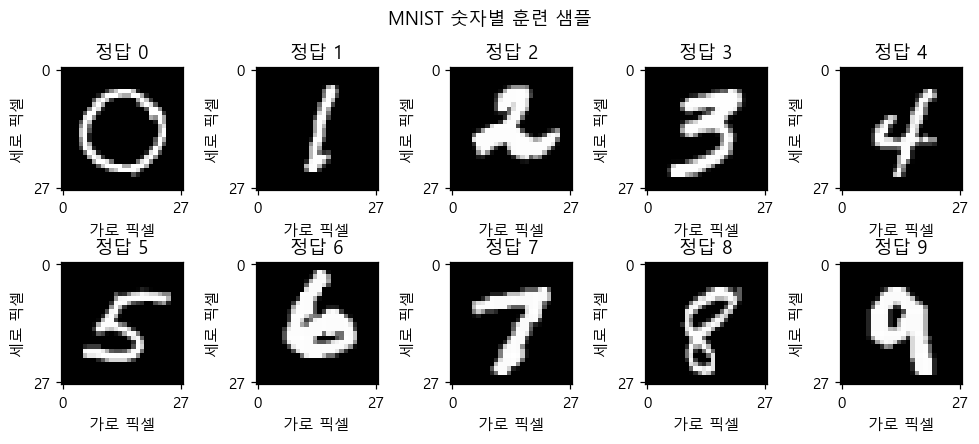

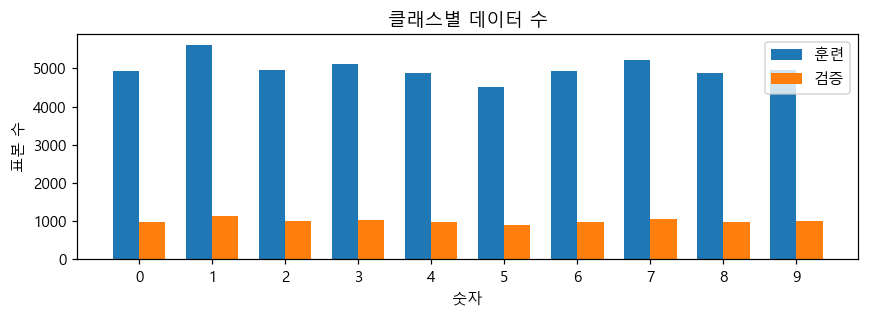

In [3]:
def load_mnist():
    path = DATA / 'mnist.npz'
    expected = '731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1'
    if not path.exists():
        temporary = path.with_suffix('.download')
        urllib.request.urlretrieve('https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz', temporary)
        temporary.replace(path)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != expected:
        raise ValueError('MNIST 파일 해시가 다릅니다. 캐시 파일을 확인하세요.')
    with np.load(path, allow_pickle=False) as data:
        arrays = [data[k].copy() for k in ('x_train','y_train','x_test','y_test')]
    assert arrays[0].shape == (60000,28,28) and arrays[2].shape == (10000,28,28)
    assert all(a.dtype == np.uint8 for a in arrays)
    return arrays, digest

def stratified_split(y, fraction=1/6, seed=SEED):
    rng, train, validation = np.random.default_rng(seed), [], []
    for label in np.unique(y):
        indices = rng.permutation(np.flatnonzero(y==label))
        count = int(round(len(indices)*fraction))
        validation.extend(indices[:count])
        train.extend(indices[count:])
    train, validation = rng.permutation(train), rng.permutation(validation)
    assert not np.intersect1d(train, validation).size
    assert len(train)+len(validation) == len(y)
    return train, validation

(raw_train, labels, raw_test, test_labels), data_hash = load_mnist()
train_idx, val_idx = stratified_split(labels)
x_train = raw_train[train_idx].reshape(-1,784).astype(np.float32)/255
x_val = raw_train[val_idx].reshape(-1,784).astype(np.float32)/255
y_train, y_val = labels[train_idx], labels[val_idx]
print('원본:',raw_train.shape, labels.shape, raw_test.shape, test_labels.shape)
print('훈련:',len(train_idx),'검증:',len(val_idx),'테스트:',len(test_labels))
print('원본 픽셀 범위:',raw_train.min(),raw_train.max(),'정규화:',x_train.min(),x_train.max())
print('SHA-256:',data_hash)
distribution = pd.DataFrame({'숫자':range(10), '훈련':np.bincount(y_train,minlength=10),
                              '검증':np.bincount(y_val,minlength=10)})
display(distribution)
fig, axes = plt.subplots(2,5,figsize=(9,4))
for digit, ax in enumerate(axes.flat):
    idx = train_idx[np.flatnonzero(y_train==digit)[0]]
    ax.imshow(raw_train[idx],cmap='gray',vmin=0,vmax=255)
    ax.set_title(f'정답 {digit}'); ax.set_xlabel('가로 픽셀'); ax.set_ylabel('세로 픽셀')
    ax.set_xticks([0,27]); ax.set_yticks([0,27])
fig.suptitle('MNIST 숫자별 훈련 샘플')
figure(fig,'samples')
fig, ax = plt.subplots(figsize=(8,3))
ax.bar(np.arange(10)-.18,distribution['훈련'],width=.36,label='훈련')
ax.bar(np.arange(10)+.18,distribution['검증'],width=.36,label='검증')
ax.set(title='클래스별 데이터 수',xlabel='숫자',ylabel='표본 수',xticks=range(10)); ax.legend()
figure(fig,'distribution')

## 5. 신경망 구조와 활성화·손실 함수
입력 784개는 픽셀, 은닉층은 획·형태의 조합을 학습하며 출력 10개는 숫자별 점수(logits)를 만든다.
기준 은닉층 128개에서 시작해 64·256개와 두 은닉층 128→64를 비교한다.
최종 구조는 검증 결과로 결정하며 노드 수만 늘리면 좋아진다고 가정하지 않는다.

배치 크기 $B$, 입력 차원 $d_{l-1}$, 출력 차원 $d_l$일 때
$A^{(l-1)}\in\mathbb R^{B\times d_{l-1}}$,
$W^{(l)}\in\mathbb R^{d_{l-1}\times d_l}$,
$b^{(l)}\in\mathbb R^{d_l}$이다.

$$Z^{(l)}=A^{(l-1)}W^{(l)}+b^{(l)},\quad A^{(l)}=\max(0,Z^{(l)})$$

ReLU는 양수 영역의 기울기를 유지하고 계산이 간단하다. 가중치는 He 초기화
$W_{ij}\sim N(0,2/d_{l-1})$, 편향은 0으로 시작한다.
출력층 Softmax는 상호 배타적인 10개 클래스의 확률을 만든다.

$$s_{ik}=z_{ik}-\max_j z_{ij},\quad p_{ik}=\frac{e^{s_{ik}}}{\sum_j e^{s_{ij}}}$$
$$L=\frac1B\sum_i\left[\log\sum_k e^{s_{ik}}-s_{i,y_i}\right]$$

정답의 확률이 작을수록 교차 엔트로피가 커진다. `log(p)` 대신 위 식을 쓰면
확률이 0으로 언더플로해도 유한한 손실을 계산할 수 있다.

## 6. 순전파·역전파·가중치 업데이트 구현
Softmax와 교차 엔트로피의 결합 미분은 $\Delta^{(L)}=(P-Y)/B$이다.
$$\frac{\partial L}{\partial W^{(l)}}=(A^{(l-1)})^T\Delta^{(l)},\quad
\frac{\partial L}{\partial b^{(l)}}=\sum_i\Delta_i^{(l)}$$
$$\Delta^{(l-1)}=(\Delta^{(l)}(W^{(l)})^T)\odot\mathbf1[Z^{(l-1)}>0]$$
모든 기울기를 구한 뒤 $W\leftarrow W-\eta\nabla_WL$, $b\leftarrow b-\eta\nabla_bL$로 갱신한다.
배치 평균은 출력 미분에서 한 번만 적용한다. 자동미분이나 프레임워크 옵티마이저는 사용하지 않는다.

In [4]:
def softmax_cross_entropy(logits, y):
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp = np.exp(shifted)
    normalizer = exp.sum(axis=1, keepdims=True)
    probability = exp/normalizer
    loss = np.mean(np.log(normalizer[:,0]) - shifted[np.arange(len(y)),y])
    return probability, float(loss)

class MLP:
    def __init__(self, sizes, seed=SEED, dtype=np.float32):
        self.sizes = list(sizes)
        rng = np.random.default_rng(seed)
        self.weights = [(rng.standard_normal((a,b))*np.sqrt(2/a)).astype(dtype)
                        for a,b in zip(sizes[:-1],sizes[1:])]
        self.biases = [np.zeros(b,dtype=dtype) for b in sizes[1:]]

    @property
    def parameter_count(self):
        return sum(w.size+b.size for w,b in zip(self.weights,self.biases))

    def forward(self,x):
        activations, preactivations = [x], []
        for layer,(w,b) in enumerate(zip(self.weights,self.biases)):
            z = activations[-1]@w+b
            preactivations.append(z)
            activations.append(np.maximum(z,0) if layer<len(self.weights)-1 else z)
        return activations, preactivations

    def loss_grad(self,x,y):
        activations, preactivations = self.forward(x)
        probability, loss = softmax_cross_entropy(activations[-1],y)
        delta = probability.copy()
        delta[np.arange(len(y)),y] -= 1
        delta /= len(y)
        dw, db = [None]*len(self.weights), [None]*len(self.biases)
        for layer in reversed(range(len(self.weights))):
            dw[layer] = activations[layer].T@delta
            db[layer] = delta.sum(axis=0)
            if layer>0:
                delta = (delta@self.weights[layer].T)*(preactivations[layer-1]>0)
        return loss,dw,db

    def step(self,dw,db,lr):
        for layer in range(len(self.weights)):
            self.weights[layer] -= lr*dw[layer]
            self.biases[layer] -= lr*db[layer]

    def state(self):
        return ([w.copy() for w in self.weights],[b.copy() for b in self.biases])

    def restore(self,state):
        self.weights = [w.copy() for w in state[0]]
        self.biases = [b.copy() for b in state[1]]

def evaluate(model,x,y,batch_size=1024):
    loss_total, correct, predictions = 0.,0,[]
    for start in range(0,len(y),batch_size):
        xb,yb = x[start:start+batch_size],y[start:start+batch_size]
        probability,loss = softmax_cross_entropy(model.forward(xb)[0][-1],yb)
        pred = probability.argmax(axis=1)
        loss_total += loss*len(yb)
        correct += int(np.count_nonzero(pred==yb))
        predictions.append(pred)
    return loss_total/len(y),correct/len(y),np.concatenate(predictions)

def gradient_check():
    rng = np.random.default_rng(7)
    x,y = rng.normal(size=(5,4)),np.array([0,1,2,1,0])
    model = MLP([4,5,3,3],seed=8,dtype=np.float64)
    _,dw,db = model.loss_grad(x,y)
    errors,eps = [],1e-5
    for array,analytic in zip(model.weights+model.biases,dw+db):
        for index in np.ndindex(array.shape):
            old = array[index]
            array[index] = old+eps
            plus = model.loss_grad(x,y)[0]
            array[index] = old-eps
            minus = model.loss_grad(x,y)[0]
            array[index] = old
            numeric = (plus-minus)/(2*eps)
            errors.append(abs(numeric-analytic[index])/max(1.,abs(numeric),abs(analytic[index])))
    return {'checked_parameters':len(errors),'max_scaled_error':float(max(errors)),'epsilon':eps}

def classification_metrics(y,pred,n_classes=10):
    cm = np.zeros((n_classes,n_classes),dtype=np.int64)
    np.add.at(cm,(y,pred),1)
    tp,support,predicted = np.diag(cm),cm.sum(axis=1),cm.sum(axis=0)
    precision = np.divide(tp,predicted,out=np.zeros(n_classes),where=predicted!=0)
    recall = np.divide(tp,support,out=np.zeros(n_classes),where=support!=0)
    f1 = np.divide(2*precision*recall,precision+recall,out=np.zeros(n_classes),where=precision+recall!=0)
    scores = dict(accuracy=float(tp.sum()/cm.sum()),macro_precision=float(precision.mean()),
                  macro_recall=float(recall.mean()),macro_f1=float(f1.mean()))
    per_class = pd.DataFrame({'digit':range(n_classes),'precision':precision,'recall':recall,
                              'f1':f1,'support':support})
    return cm,scores,per_class

check_results = implementation_checks(globals())
print(json.dumps(check_results,ensure_ascii=False,indent=2))

{
  "checks": "5/5 passed",
  "gradient": {
    "checked_parameters": 55,
    "max_scaled_error": 3.9785440567041697e-11,
    "epsilon": 1e-05
  },
  "toy_initial_loss": 1.1069433293863713,
  "toy_final_loss": 0.050498227215025844
}


## 7. 학습과 모델 선택 규칙
매 에포크마다 훈련 순서를 섞어 미니배치 SGD를 수행한다. 모멘텀·정규화·데이터 증강은 사용하지 않는다.
훈련 손실과 정확도도 해당 에포크의 **갱신 완료 후 전체 훈련 집합**에서 측정한다.
시간에는 미니배치 학습과 훈련·검증 평가를 포함한다.

각 실험은 10에포크를 끝까지 수행하고 검증 정확도가 가장 높은 에포크의 파라미터를 메모리에서 복원한다.
검증 정확도 동률은 검증 손실이 낮은 에포크를 선택한다. 실험 간 동률은 검증 손실, 파라미터 수 순으로 정한다.
테스트 정확도로 모델을 고르지 않는다. 체크포인트 파일은 만들지 않는다.

In [5]:
def fit(config):
    model = MLP([784]+config['hidden']+[10])
    initial = model.state()
    rng = np.random.default_rng(SEED+1)
    history,best_key,best_state,best_epoch = [],None,None,None
    started = time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        epoch_start = time.perf_counter()
        order = rng.permutation(len(y_train))
        for start in range(0,len(y_train),config['batch']):
            idx = order[start:start+config['batch']]
            _,dw,db = model.loss_grad(x_train[idx],y_train[idx])
            model.step(dw,db,config['lr'])
        train_loss,train_acc,_ = evaluate(model,x_train,y_train)
        val_loss,val_acc,_ = evaluate(model,x_val,y_val)
        assert np.isfinite(train_loss) and np.isfinite(val_loss)
        row = dict(epoch=epoch,train_loss=train_loss,train_accuracy=train_acc,
                   val_loss=val_loss,val_accuracy=val_acc,seconds=time.perf_counter()-epoch_start)
        history.append(row)
        key = (val_acc,-val_loss)
        if best_key is None or key>best_key:
            best_key,best_state,best_epoch = key,model.state(),epoch
        print(f"{config['id']} epoch {epoch:02d} | train {train_acc:.4%} | val {val_acc:.4%} | loss {val_loss:.4f}",flush=True)
    seconds = time.perf_counter()-started
    model.restore(best_state)
    selected = history[best_epoch-1]
    result = dict(config,epochs=EPOCHS,best_epoch=best_epoch,architecture=model.sizes,
                  parameters=model.parameter_count,seconds=seconds,history=history,
                  train_accuracy=selected['train_accuracy'],val_accuracy=selected['val_accuracy'],
                  train_loss=selected['train_loss'],val_loss=selected['val_loss'],
                  weight_l2_change=[float(np.linalg.norm(w-old)) for w,old in zip(model.weights,initial[0])],
                  weight_relative_change=[float(np.linalg.norm(w-old)/np.linalg.norm(old)) for w,old in zip(model.weights,initial[0])],
                  bias_l2_change=[float(np.linalg.norm(b-old)) for b,old in zip(model.biases,initial[1])])
    return model,result

configs = [
    {'id':'E1','hidden':[128],'lr':.01,'batch':64,'reason':'기준 모델'},
    {'id':'E2','hidden':[64],'lr':.01,'batch':64,'reason':'노드 감소: 계산량과 표현력 비교'},
    {'id':'E3','hidden':[256],'lr':.01,'batch':64,'reason':'노드 증가: 표현력 증가 효과'},
    {'id':'E4','hidden':[128],'lr':.001,'batch':64,'reason':'학습률 감소: 수렴 속도 비교'},
    {'id':'E5','hidden':[128],'lr':.1,'batch':64,'reason':'학습률 증가: 빠른 갱신 효과'},
    {'id':'E6','hidden':[128,64],'lr':.01,'batch':64,'reason':'은닉층 추가: 깊이의 효과'},
    {'id':'E7','hidden':[128],'lr':.01,'batch':128,'reason':'배치 증가: 갱신 횟수와 효율 비교'}]
models,results = {},[]
baseline_model,baseline = fit(configs[0])
models['E1'] = baseline_model
results.append(baseline)
display(pd.DataFrame(baseline['history']))

E1 epoch 01 | train 86.8677% | val 86.9213% | loss 0.5188


E1 epoch 02 | train 89.3438% | val 89.0411% | loss 0.4031


E1 epoch 03 | train 90.4838% | val 90.0510% | loss 0.3598


E1 epoch 04 | train 91.0478% | val 90.6109% | loss 0.3334


E1 epoch 05 | train 91.7938% | val 91.1109% | loss 0.3149


...

E1 epoch 07 | train 92.4958% | val 91.8608% | loss 0.2863


E1 epoch 08 | train 92.8019% | val 92.1108% | loss 0.2752


E1 epoch 09 | train 93.0659% | val 92.3808% | loss 0.2654


E1 epoch 10 | train 93.3319% | val 92.5607% | loss 0.2572


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,seconds
0,1,0.511602,0.868677,0.518795,0.869213,1.060782
1,2,0.391430,0.893438,0.403089,0.890411,0.983990
2,3,0.345070,0.904838,0.359805,0.900510,0.980176
3,4,0.317593,0.910478,0.333396,0.906109,0.984050
4,5,0.296973,0.917938,0.314853,0.911109,0.964012
5,6,0.280613,0.920838,0.299140,0.915508,0.947214
6,7,0.266683,0.924958,0.286324,0.918608,0.969877
7,8,0.254990,0.928019,0.275170,0.921108,0.955697
8,9,0.244725,0.930659,0.265393,0.923808,0.941520
9,10,0.235256,0.933319,0.257183,0.925607,0.944915


## 8. 기준 모델 학습 곡선
에포크별 훈련·검증 손실과 정확도를 비교한다. 두 곡선의 차이는 일반화 차이를 살펴보는 단서다.
유한한 학습 예산에서의 성능을 기록하며 곡선만으로 수렴이나 과적합을 단정하지 않는다.

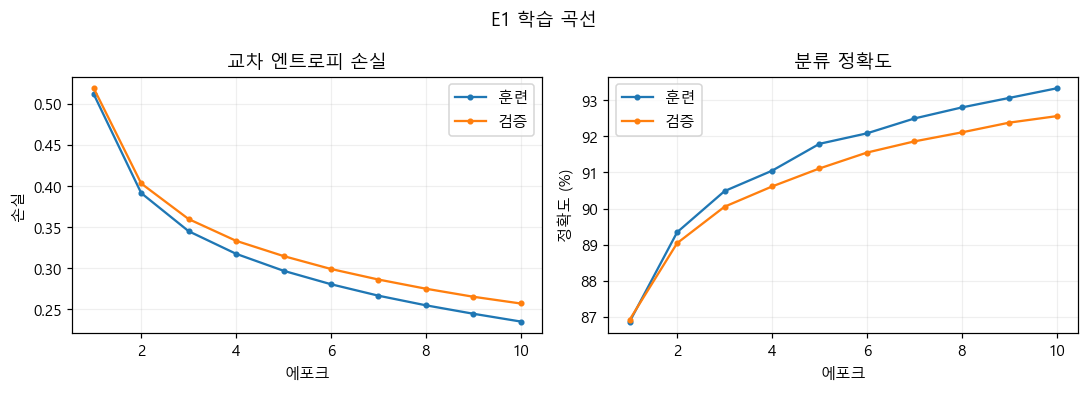

In [6]:
def learning_curves(result,name):
    h = pd.DataFrame(result['history'])
    fig,axes = plt.subplots(1,2,figsize=(10,3.6))
    for key,label in [('train_loss','훈련'),('val_loss','검증')]:
        axes[0].plot(h['epoch'],h[key],marker='.',label=label)
    for key,label in [('train_accuracy','훈련'),('val_accuracy','검증')]:
        axes[1].plot(h['epoch'],100*h[key],marker='.',label=label)
    axes[0].set(title='교차 엔트로피 손실',xlabel='에포크',ylabel='손실')
    axes[1].set(title='분류 정확도',xlabel='에포크',ylabel='정확도 (%)')
    for ax in axes:
        ax.legend(); ax.grid(alpha=.2)
    fig.suptitle(f"{result['id']} 학습 곡선")
    figure(fig,name)
learning_curves(baseline,'baseline_curves')

## 9. 정확도 개선 실험
E2~E7은 기준 E1에서 주요 변수 하나씩만 바꾼다. 데이터 분할·초기화 시드·셔플 시드·에포크 수는 고정한다.
동일한 구조에서는 같은 초기 가중치를 사용하므로 학습률·배치 비교에서 출발점이 같다.
구조가 달라지면 파라미터 차원이 달라 같은 행렬을 사용할 수는 없다.
배치 크기가 달라지면 에포크당 갱신 횟수도 달라지므로 동일한 갱신 횟수 비교는 아니다.
단일 시드 결과이므로 작은 차이를 통계적으로 유의한 차이라고 해석하지 않는다.

In [7]:
for config in configs[1:]:
    model,result = fit(config)
    models[config['id']] = model
    results.append(result)
    # 중간 실행 기록만 보관한다. 테스트 결과는 아직 존재하지 않는다.
    (OUT/'experiments.json').write_text(json.dumps(results,ensure_ascii=False,indent=2),encoding='utf-8')

E2 epoch 01 | train 86.4577% | val 86.6013% | loss 0.5301


E2 epoch 02 | train 89.1598% | val 88.8411% | loss 0.4098


E2 epoch 03 | train 90.2658% | val 89.8410% | loss 0.3657


E2 epoch 04 | train 90.8778% | val 90.2710% | loss 0.3397


E2 epoch 05 | train 91.4898% | val 90.9109% | loss 0.3226


...

E7 epoch 06 | train 90.3958% | val 90.0910% | loss 0.3587


E7 epoch 07 | train 90.8518% | val 90.4010% | loss 0.3443


E7 epoch 08 | train 91.1858% | val 90.6109% | loss 0.3325


E7 epoch 09 | train 91.3918% | val 90.8209% | loss 0.3222


E7 epoch 10 | train 91.6898% | val 91.0909% | loss 0.3137


## 10. 실험 결과 비교와 최종 모델 선정
표의 훈련·검증 지표는 각 실험의 **선택된 최우수 검증 에포크**에서 함께 측정한 수치다.
총 에포크 수와 선택 에포크를 구분하고, 학습 시간은 10에포크 전체 수행 시간이다.
정확도 변화 단위는 기준 모델 대비 퍼센트포인트(%p)다.

,실험,구조,은닉 노드,학습률,배치,총 에포크,선택 에포크,훈련 정확도 (%),검증 정확도 (%),검증 손실,시간 (초),변화 (%p),분석
0,E1,784 → 128 → 10,[128],0.010,64,10,10,93.3319,92.5607,0.257183,9.74,0.0000,기준 대비 0.00%p 동일. 비교 기준이다.
1,E2,784 → 64 → 10,[64],0.010,64,10,10,93.1119,92.3608,0.267454,5.28,-0.2000,기준 대비 0.20%p 하락. 노드 감소로 파라미터와 표현 용량이 함께 감소한다.
2,E3,784 → 256 → 10,[256],0.010,64,10,10,93.6979,93.1007,0.248856,20.06,0.5399,기준 대비 0.54%p 상승. 넓은 은닉층은 표현 용량을 늘리지만 연산량도 증가한다.
3,E4,784 → 128 → 10,[128],0.001,64,10,10,86.9917,86.8513,0.517119,9.48,-5.7094,기준 대비 5.71%p 하락. 작은 학습률은 같은 에포크 예산에서 갱신 폭이 작아 ...
4,E5,784 → 128 → 10,[128],0.100,64,10,10,98.6240,97.1503,0.093870,9.84,4.5895,기준 대비 4.59%p 상승. 큰 학습률은 갱신 폭을 키워 수렴 속도를 바꾸지만 불...
5,E6,784 → 128 → 64 → 10,"[128, 64]",0.010,64,10,10,95.0719,94.1306,0.198512,11.17,1.5698,기준 대비 1.57%p 상승. 깊이를 늘려 비선형 조합 단계를 추가하지만 최적화와 ...
6,E7,784 → 128 → 10,[128],0.010,128,10,10,91.6898,91.0909,0.313713,9.46,-1.4699,기준 대비 1.47%p 하락. 배치 증가로 에포크당 갱신 횟수가 줄어드는 효과도 함...


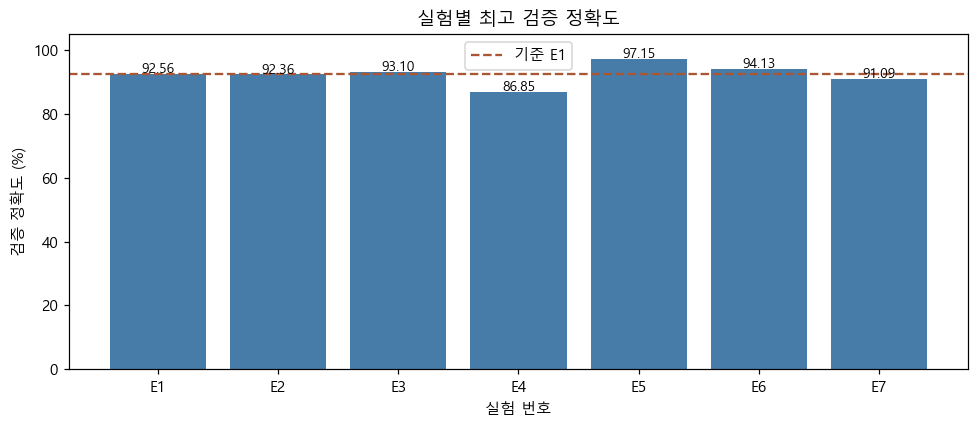

최종 선택: **E5**, 구조 **784 → 128 → 10**, 검증 정확도 **97.1503%**, 파라미터 **101,770개**.

,층,입력,출력,활성화,가중치,편향,합계
0,1,784,128,ReLU,100352,128,100480
1,2,128,10,Softmax,1280,10,1290


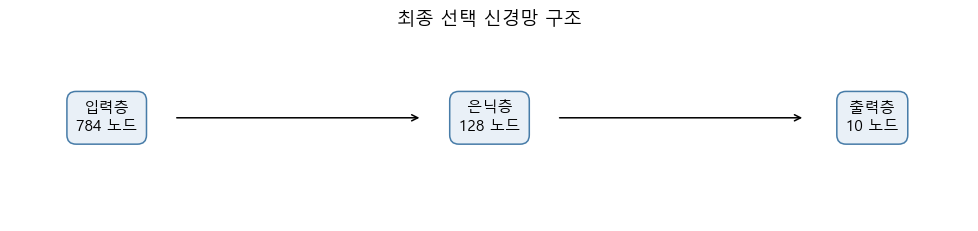

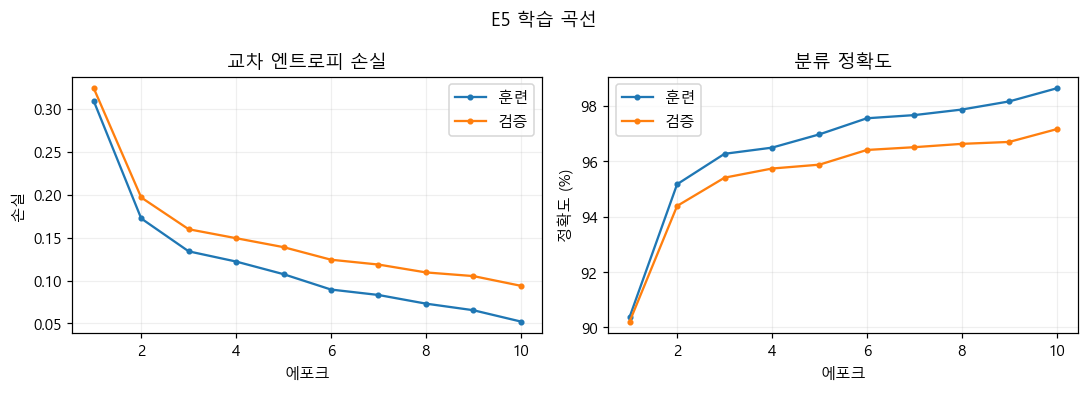

In [8]:
mechanisms = {
    'E1':'비교 기준이다.',
    'E2':'노드 감소로 파라미터와 표현 용량이 함께 감소한다.',
    'E3':'넓은 은닉층은 표현 용량을 늘리지만 연산량도 증가한다.',
    'E4':'작은 학습률은 같은 에포크 예산에서 갱신 폭이 작아 수렴이 느릴 수 있다.',
    'E5':'큰 학습률은 갱신 폭을 키워 수렴 속도를 바꾸지만 불안정해질 가능성도 있다.',
    'E6':'깊이를 늘려 비선형 조합 단계를 추가하지만 최적화와 계산 비용도 달라진다.',
    'E7':'배치 증가로 에포크당 갱신 횟수가 줄어드는 효과도 함께 포함된다.'}
rows = []
for r in results:
    delta = 100*(r['val_accuracy']-baseline['val_accuracy'])
    r['delta_pp'] = delta
    direction = '상승' if delta>0 else '하락' if delta<0 else '동일'
    r['analysis'] = f"기준 대비 {abs(delta):.2f}%p {direction}. "+mechanisms[r['id']]
    rows.append({'실험':r['id'],'구조':' → '.join(map(str,r['architecture'])),
                 '은닉 노드':str(r['hidden']),'학습률':r['lr'],'배치':r['batch'],
                 '총 에포크':r['epochs'],'선택 에포크':r['best_epoch'],
                 '훈련 정확도 (%)':round(100*r['train_accuracy'],4),
                 '검증 정확도 (%)':round(100*r['val_accuracy'],4),
                 '검증 손실':round(r['val_loss'],6),'시간 (초)':round(r['seconds'],2),
                 '변화 (%p)':round(delta,4),'분석':r['analysis']})
comparison = pd.DataFrame(rows)
display(comparison)
fig,ax = plt.subplots(figsize=(9,4))
bars = ax.bar([r['id'] for r in results],[100*r['val_accuracy'] for r in results],color='#477ca8')
for bar,r in zip(bars,results):
    ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.3,f"{100*r['val_accuracy']:.2f}",ha='center',fontsize=9)
ax.set(title='실험별 최고 검증 정확도',xlabel='실험 번호',ylabel='검증 정확도 (%)',ylim=(0,105))
ax.axhline(100*baseline['val_accuracy'],color='#aa5533',linestyle='--',label='기준 E1')
ax.legend(); figure(fig,'comparison')
best = max(results,key=lambda r:(r['val_accuracy'],-r['val_loss'],-r['parameters']))
final_model = models[best['id']]
assert all('test_accuracy' not in r for r in results)
display(Markdown(f"최종 선택: **{best['id']}**, 구조 **{' → '.join(map(str,best['architecture']))}**, "
                 f"검증 정확도 **{best['val_accuracy']:.4%}**, 파라미터 **{best['parameters']:,}개**."))
layer_rows = []
for i,(a,b) in enumerate(zip(best['architecture'][:-1],best['architecture'][1:]),1):
    layer_rows.append({'층':i,'입력':a,'출력':b,'활성화':'Softmax' if i==len(best['architecture'])-1 else 'ReLU',
                      '가중치':a*b,'편향':b,'합계':a*b+b})
display(pd.DataFrame(layer_rows))
fig,ax = plt.subplots(figsize=(9,2.2))
ax.axis('off')
for i,n in enumerate(best['architecture']):
    x = .1+i*.8/(len(best['architecture'])-1)
    ax.text(x,.55,f"{['입력층' if i==0 else '출력층' if i==len(best['architecture'])-1 else '은닉층'][0]}\n{n} 노드",
            ha='center',va='center',bbox=dict(boxstyle='round,pad=.6',fc='#e9f0f7',ec='#477ca8'),transform=ax.transAxes)
    if i<len(best['architecture'])-1:
        nx=.1+(i+1)*.8/(len(best['architecture'])-1)
        ax.annotate('',xy=(nx-.07,.55),xytext=(x+.07,.55),xycoords='axes fraction',arrowprops=dict(arrowstyle='->'))
ax.set_title('최종 선택 신경망 구조')
figure(fig,'architecture')
learning_curves(best,'final_curves')

## 11. 최종 테스트 평가와 다중 클래스 지표
지금부터 최종 모델을 고정한 채 공식 테스트 10,000개를 한 번 추론한다.
그 예측 배열을 재사용해 정확도·손실·혼동 행렬·오분류 사례를 계산한다.
Precision·Recall·F1은 숫자별 값을 계산한 뒤 동일 가중치로 평균한 **macro 평균**이다.
F1은 macro precision과 macro recall의 조화평균이 아니라 클래스별 F1의 평균이다.
테스트 결과를 본 뒤 설정이나 모델을 바꾸지 않는다.

,accuracy,macro_precision,macro_recall,macro_f1,test_loss,test_count,correct,passed_80_percent
0,0.9746,0.974517,0.974397,0.974415,0.084811,10000,9746,True


,digit,precision,recall,f1,support
0,0,0.976815,0.988776,0.982759,980
1,1,0.987698,0.990308,0.989001,1135
2,2,0.983235,0.966085,0.974585,1032
3,3,0.963107,0.982178,0.972549,1010
4,4,0.978462,0.971487,0.974962,982
5,5,0.978507,0.969731,0.974099,892
6,6,0.967179,0.984342,0.975685,958
7,7,0.968872,0.968872,0.968872,1028
8,8,0.976939,0.956879,0.966805,974
9,9,0.964356,0.965312,0.964834,1009


실제 테스트 정확도: 97.4600%, 80% 이상: True


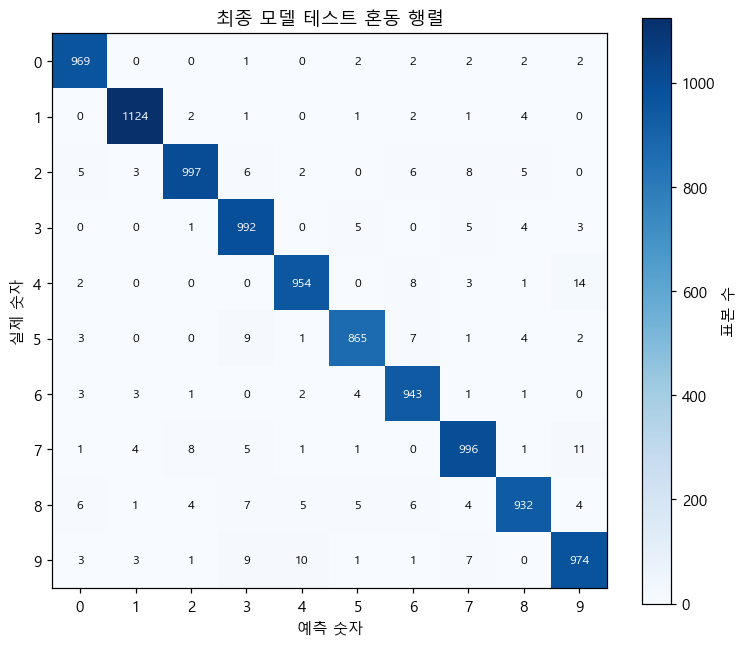

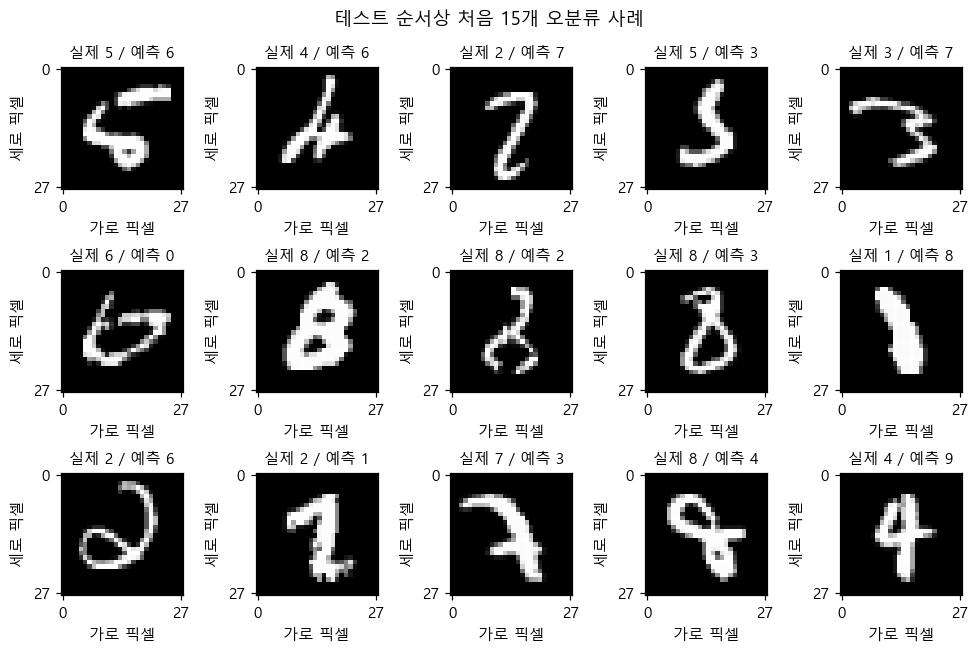

,실제,예측,횟수
0,4,9,14
1,7,9,11
2,9,4,10
3,9,3,9
4,5,3,9


In [9]:
x_test = raw_test.reshape(-1,784).astype(np.float32)/255
test_loss,test_accuracy,test_predictions = evaluate(final_model,x_test,test_labels)
cm,metrics,per_class = classification_metrics(test_labels,test_predictions)
assert metrics['accuracy'] == test_accuracy
assert cm.sum() == 10000 and np.trace(cm) == np.count_nonzero(test_predictions==test_labels)
metrics['test_loss'] = test_loss
metrics['test_count'] = len(test_labels)
metrics['correct'] = int(np.trace(cm))
metrics['passed_80_percent'] = bool(test_accuracy>=.8)
display(pd.DataFrame([metrics]))
display(per_class)
print(f"실제 테스트 정확도: {test_accuracy:.4%}, 80% 이상: {metrics['passed_80_percent']}")
fig,ax = plt.subplots(figsize=(7,6))
im = ax.imshow(cm,cmap='Blues')
for i in range(10):
    for j in range(10):
        ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=8,
                color='white' if cm[i,j]>cm.max()*.5 else 'black')
ax.set(title='최종 모델 테스트 혼동 행렬',xlabel='예측 숫자',ylabel='실제 숫자',xticks=range(10),yticks=range(10))
fig.colorbar(im,ax=ax,label='표본 수')
figure(fig,'confusion')
errors = np.flatnonzero(test_predictions!=test_labels)
fig,axes = plt.subplots(3,5,figsize=(9,6))
for ax,index in zip(axes.flat,errors[:15]):
    ax.imshow(raw_test[index],cmap='gray',vmin=0,vmax=255)
    ax.set_title(f'실제 {test_labels[index]} / 예측 {test_predictions[index]}',fontsize=10)
    ax.set_xlabel('가로 픽셀'); ax.set_ylabel('세로 픽셀')
    ax.set_xticks([0,27]); ax.set_yticks([0,27])
for ax in list(axes.flat)[min(len(errors),15):]:
    ax.axis('off')
fig.suptitle('테스트 순서상 처음 15개 오분류 사례')
figure(fig,'errors')
offdiag = cm.copy(); np.fill_diagonal(offdiag,0)
pairs = sorted([(int(offdiag[i,j]),i,j) for i in range(10) for j in range(10) if i!=j],reverse=True)[:5]
display(pd.DataFrame([{'실제':i,'예측':j,'횟수':n} for n,i,j in pairs]))

## 12. 가중치 변화와 결과 종합 분석
다음 수치는 초기 상태와 **선택된 에포크**의 상태를 비교한다.
가중치의 Frobenius norm 변화와 상대 변화, 편향의 L2 변화를 기록해 실제 갱신을 확인한다.
변화량이 크다는 사실만으로 성능 개선 원인을 증명할 수는 없다.
실험 비교는 학습 설정에 따른 결과이며 각 요인의 일반적인 우월성을 입증하는 반복 실험은 아니다.

In [10]:
weight_rows = [{'층':i+1,'가중치 변화 L2':a,'가중치 상대 변화':b,'편향 변화 L2':c}
               for i,(a,b,c) in enumerate(zip(best['weight_l2_change'],best['weight_relative_change'],best['bias_l2_change']))]
display(pd.DataFrame(weight_rows))
gap = 100*(best['train_accuracy']-best['val_accuracy'])
analysis_text = (f"기준 E1의 검증 정확도는 {baseline['val_accuracy']:.4%}이고, 최종 {best['id']}는 "
                 f"{best['val_accuracy']:.4%}로 {best['delta_pp']:+.2f}%p 변화했다. "
                 f"최종 모델은 {' → '.join(map(str,best['architecture']))} 구조이며, "
                 f"학습률 {best['lr']}, 배치 {best['batch']}, 총 {EPOCHS}에포크 중 {best['best_epoch']}에포크가 선택되었다. "
                 f"이 비교 범위에서 검증 정확도가 가장 높아 해당 은닉층 개수와 노드 수를 채택했다. "
                 f"선택 에포크의 훈련-검증 정확도 차이는 {gap:.2f}%p다. "
                 f"테스트는 {metrics['correct']:,}/{len(test_labels):,}개를 맞혀 {test_accuracy:.4%}이며, "
                 f"80% 목표 {'달성' if test_accuracy>=.8 else '미달'}이다.")
display(Markdown(analysis_text))
for r in results:
    display(Markdown(f"**{r['id']}** ({r['reason']}): {r['analysis']} 검증 손실 {r['val_loss']:.5f}, 시간 {r['seconds']:.2f}초."))
pair_text = ', '.join(f'{i}→{j}: {n}개' for n,i,j in pairs)
display(Markdown('빈도가 높은 실제→예측 오분류는 '+pair_text+'이다. '
                 '예시에서 획의 연결·기울기·형태가 비슷한 숫자를 비교할 수 있다. '
                 '이는 시각적 해석이며 오분류 원인을 확정하는 인과 분석은 아니다.'))
summary = {'environment':environment,'data_sha256':data_hash,
           'train_count':len(y_train),'validation_count':len(y_val),'test_count':len(test_labels),
           'distribution':distribution.to_dict(orient='records'), 'verification':check_results,
           'experiments':results,'selected_id':best['id'],'selected':best,'metrics':metrics,
           'per_class':per_class.to_dict(orient='records'),'confusion_matrix':cm.tolist(),
           'top_errors':[{'count':n,'actual':i,'predicted':j} for n,i,j in pairs],
           'analysis':analysis_text,'weight_changes':weight_rows}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print('실제 실행 결과 저장:',OUT/'summary.json')

,층,가중치 변화 L2,가중치 상대 변화,편향 변화 L2
0,1,11.089699,0.690521,0.760531
1,2,7.623845,1.678466,0.420838


기준 E1의 검증 정확도는 92.5607%이고, 최종 E5는 97.1503%로 +4.59%p 변화했다. 최종 모델은 784 → 128 → 10 구조이며, 학습률 0.1, 배치 64, 총 10에포크 중 10에포크가 선택되었다. 이 비교 범위에서 검증 정확도가 가장 높아 해당 은닉층 개수와 노드 수를 채택했다. 선택 에포크의 훈련-검증 정확도 차이는 1.47%p다. 테스트는 9,746/10,000개를 맞혀 97.4600%이며, 80% 목표 달성이다.

**E1** (기준 모델): 기준 대비 0.00%p 동일. 비교 기준이다. 검증 손실 0.25718, 시간 9.74초.

**E2** (노드 감소: 계산량과 표현력 비교): 기준 대비 0.20%p 하락. 노드 감소로 파라미터와 표현 용량이 함께 감소한다. 검증 손실 0.26745, 시간 5.28초.

**E3** (노드 증가: 표현력 증가 효과): 기준 대비 0.54%p 상승. 넓은 은닉층은 표현 용량을 늘리지만 연산량도 증가한다. 검증 손실 0.24886, 시간 20.06초.

...

**E5** (학습률 증가: 빠른 갱신 효과): 기준 대비 4.59%p 상승. 큰 학습률은 갱신 폭을 키워 수렴 속도를 바꾸지만 불안정해질 가능성도 있다. 검증 손실 0.09387, 시간 9.84초.

**E6** (은닉층 추가: 깊이의 효과): 기준 대비 1.57%p 상승. 깊이를 늘려 비선형 조합 단계를 추가하지만 최적화와 계산 비용도 달라진다. 검증 손실 0.19851, 시간 11.17초.

**E7** (배치 증가: 갱신 횟수와 효율 비교): 기준 대비 1.47%p 하락. 배치 증가로 에포크당 갱신 횟수가 줄어드는 효과도 함께 포함된다. 검증 손실 0.31371, 시간 9.46초.

빈도가 높은 실제→예측 오분류는 4→9: 14개, 7→9: 11개, 9→4: 10개, 9→3: 9개, 5→3: 9개이다. 예시에서 획의 연결·기울기·형태가 비슷한 숫자를 비교할 수 있다. 이는 시각적 해석이며 오분류 원인을 확정하는 인과 분석은 아니다.

실제 실행 결과 저장: C:\Projects\ML_practice\.mnist_work\results\summary.json


## 13. 결론과 한계 및 향후 개선
NumPy만으로 다층 신경망의 핵심 계산을 직접 구현하고 기울기 검증 후 동일한 분할에서 학습 설정을 비교했다.
위의 실제 실행 결과로 목표 달성 여부를 판단한다. 모델 선택은 검증 집합에 한정했으며
테스트 집합의 예측을 재사용해 모든 최종 지표를 계산했다.

한계는 단일 난수 시드·10에포크의 제한된 예산, 평탄화 MLP가 이미지의 공간 구조를 직접 활용하지 못한다는 점,
여러 조건을 같은 검증 집합으로 선택해 검증 성능에도 선택 편향이 생길 수 있다는 점이다.
작은 차이는 여러 시드의 평균·표준편차로 재확인할 필요가 있다.
향후에는 별도의 실험으로 학습률 스케줄, 정규화, 데이터 증강, CNN 등을 비교할 수 있다.
이번 결과를 본 뒤 테스트 성능에 맞춰 추가 튜닝하지 않았다.

## 14. 참고 자료와 파일 관리
- Keras MNIST 데이터 설명: https://keras.io/api/datasets/mnist/
- Keras 공식 MNIST 로더·SHA-256: https://github.com/keras-team/keras/blob/master/keras/src/datasets/mnist.py
- 데이터 배포: https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz

최종 제출물은 본 노트북과 `신경망구현_황태하_보고서.pdf` 두 개다.
`.gitignore`는 `.mnist_work/`, Python 캐시·가상환경, Jupyter 체크포인트, 로그·임시 파일만 제외한다.
기존 추적 파일과 다른 과제 노트북은 변경하지 않는다. 커밋·푸시는 실행하지 않는다.